In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from google.colab import files
files.upload()

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

!kaggle datasets download sumn2u/garbage-classification-v2

Saving kaggle (2).json to kaggle (2).json
cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/sumn2u/garbage-classification-v2
License(s): MIT
100% 1.07G/1.07G [00:08<00:00, 138MB/s]



In [3]:
!unzip "/content/garbage-classification-v2.zip" -d "/content/garbage-classification"

Streaming output truncated to the last 5000 lines.
  inflating: /content/garbage-classification/standardized_384/metal/metal_789.jpg  
  inflating: /content/garbage-classification/standardized_384/metal/metal_79.jpg  
  inflating: /content/garbage-classification/standardized_384/metal/metal_790.jpg  
  inflating: /content/garbage-classification/standardized_384/metal/metal_791.jpg  
  inflating: /content/garbage-classification/standardized_384/metal/metal_792.jpg  
  inflating: /content/garbage-classification/standardized_384/metal/metal_793.jpg  
  inflating: /content/garbage-classification/standardized_384/metal/metal_794.jpg  
  inflating: /content/garbage-classification/standardized_384/metal/metal_795.jpg  
  inflating: /content/garbage-classification/standardized_384/metal/metal_796.jpg  
  inflating: /content/garbage-classification/standardized_384/metal/metal_797.jpg  
  inflating: /content/garbage-classification/standardized_384/metal/metal_798.jpg  
  inflating: /content/garb

/tmp/ipykernel_3680/3421775691.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Category', y='Count', palette='viridis')


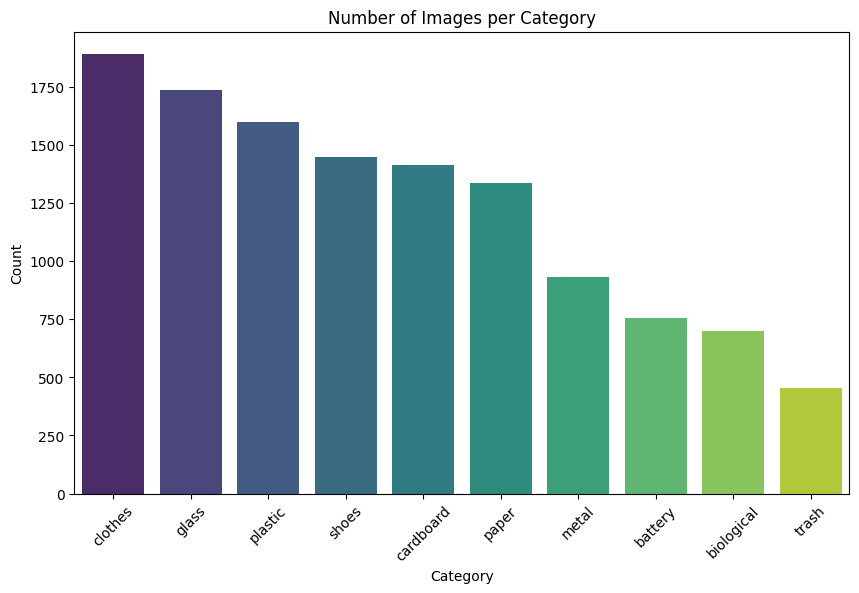

     Category  Count
0     clothes   1892
1       glass   1736
2     plastic   1597
9       shoes   1449
5   cardboard   1411
6       paper   1336
3       metal    930
4     battery    756
7  biological    699
8       trash    453


In [4]:
import os
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

data_dir = '/content/garbage-classification/original'


categories = [d for d in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, d))]

data_counts = []
for cat in categories:
    count = len(os.listdir(os.path.join(data_dir, cat)))
    data_counts.append({'Category': cat, 'Count': count})

df = pd.DataFrame(data_counts).sort_values(by='Count', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=df, x='Category', y='Count', palette='viridis')
plt.title('Number of Images per Category')
plt.xticks(rotation=45)
plt.show()

print(df)

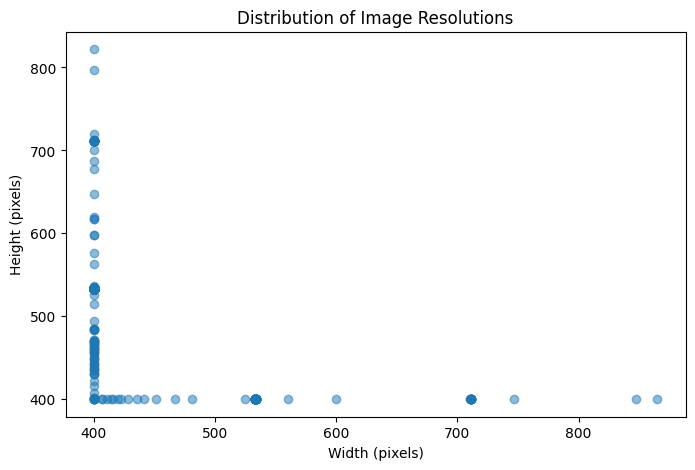

Average Width: 424.99, Average Height: 514.49


In [5]:
from PIL import Image
import numpy as np

widths = []
heights = []
sample_size = 500

count = 0
for root, dirs, files in os.walk(data_dir):
    for file in files:
        if file.lower().endswith(('.png', '.jpg', '.jpeg')) and count < sample_size:
            img = Image.open(os.path.join(root, file))
            w, h = img.size
            widths.append(w)
            heights.append(h)
            count += 1

plt.figure(figsize=(8, 5))
plt.scatter(widths, heights, alpha=0.5)
plt.xlabel('Width (pixels)')
plt.ylabel('Height (pixels)')
plt.title('Distribution of Image Resolutions')
plt.show()

print(f"Average Width: {np.mean(widths):.2f}, Average Height: {np.mean(heights):.2f}")

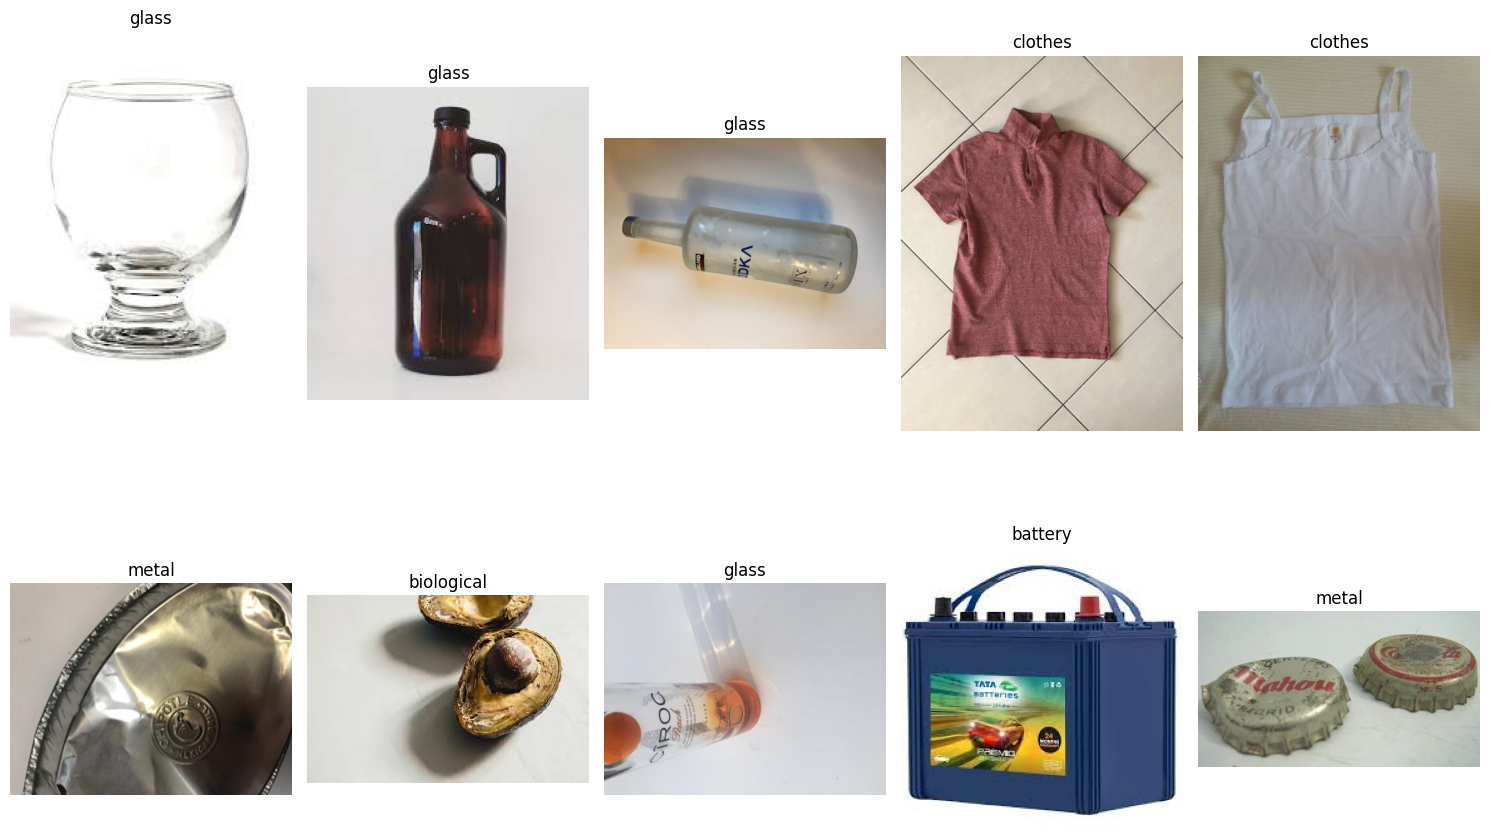

In [6]:
import random
import matplotlib.image as mpimg

plt.figure(figsize=(15, 10))

all_images = []
for root, dirs, files in os.walk(data_dir):
    for file in files:
        if file.lower().endswith(('.png', '.jpg', '.jpeg')):
            all_images.append(os.path.join(root, file))

sample_images = random.sample(all_images, 10)

for i, img_path in enumerate(sample_images):
    plt.subplot(2, 5, i + 1)
    img = mpimg.imread(img_path)
    plt.imshow(img)
    plt.title(os.path.basename(os.path.dirname(img_path)))
    plt.axis('off')

plt.tight_layout()
plt.show()

In [7]:
def get_color_stats(img_path):
    img = Image.open(img_path).convert('RGB')
    img_np = np.array(img)
    return np.mean(img_np, axis=(0, 1))

color_stats = [get_color_stats(p) for p in random.sample(all_images, 100)]
avg_rgb = np.mean(color_stats, axis=0)

print(f"Average Red intensity: {avg_rgb[0]:.2f}")
print(f"Average Green intensity: {avg_rgb[1]:.2f}")
print(f"Average Blue intensity: {avg_rgb[2]:.2f}")

Average Red intensity: 163.37
Average Green intensity: 149.83
Average Blue intensity: 140.51


cleaning


In [8]:
import os
from PIL import Image

data_dir = '/content/garbage-classification/original'

def clean_dataset(path):
    for root, dirs, files in os.walk(path):
        for file in files:
            file_path = os.path.join(root, file)

            if not file.lower().endswith(('.png', '.jpg', '.jpeg')):
                os.remove(file_path)
                continue

            try:
                img = Image.open(file_path)
                img.verify()
            except (IOError, SyntaxError):
                print(f'Deleting corrupted image: {file_path}')
                os.remove(file_path)

clean_dataset(data_dir)

print("Dataset cleaning completed.")

Dataset cleaning completed.


split


In [9]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split


data_transforms = {
    'train': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomVerticalFlip(),
        transforms.RandomRotation(30),
        transforms.ColorJitter(brightness=0.2, contrast=0.2),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406],
                             [0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406],
                             [0.229, 0.224, 0.225])
    ]),
}

data_dir = '/content/garbage-classification/original'

temp_dataset_for_split = datasets.ImageFolder(data_dir)

train_idx, temp_idx = train_test_split(
    list(range(len(temp_dataset_for_split))),
    test_size=0.3,
    random_state=42,
    stratify=temp_dataset_for_split.targets
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.5,
    random_state=42,
    stratify=[temp_dataset_for_split.targets[i] for i in temp_idx]
)

full_train_dataset_transformed = datasets.ImageFolder(data_dir, transform=data_transforms['train'])
full_val_dataset_transformed = datasets.ImageFolder(data_dir, transform=data_transforms['val'])
full_test_dataset_transformed = datasets.ImageFolder(data_dir, transform=data_transforms['val'])

train_data = Subset(full_train_dataset_transformed, train_idx)
val_data = Subset(full_val_dataset_transformed, val_idx)
test_data = Subset(full_test_dataset_transformed, test_idx)

class_names = temp_dataset_for_split.classes


print(f"Total images: {len(temp_dataset_for_split)}")
print(f"Train (70%): {len(train_data)}")
print(f"Validation (15%): {len(val_data)}")
print(f"Test (15%): {len(test_data)}")

Total images: 12259
Train (70%): 8581
Validation (15%): 1839
Test (15%): 1839


Augmentation Visualization

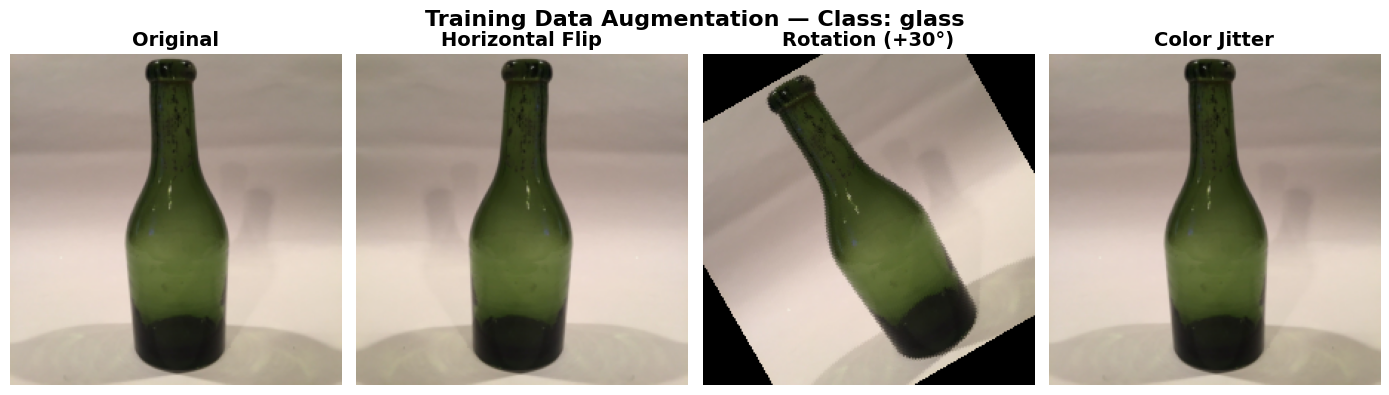

In [27]:
import matplotlib.pyplot as plt
from PIL import Image
import random
import os
from torchvision import transforms

# Select one random class from the actual dataset
selected_class = random.choice(class_names)
class_path = os.path.join(data_dir, selected_class)

# Get image files from the selected class
image_files = [
    f for f in os.listdir(class_path)
    if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.webp'))
]

# Select one real image
image_path = os.path.join(class_path, random.choice(image_files))
original = Image.open(image_path).convert("RGB")

# Resize to model input size
original_resized = transforms.Resize((224, 224))(original)

# Show individual augmentations used in training
flipped = transforms.RandomHorizontalFlip(p=1.0)(original_resized)

rotated = transforms.RandomRotation(
    degrees=(30, 30)
)(original_resized)

jittered = transforms.ColorJitter(
    brightness=0.2,
    contrast=0.2
)(original_resized)

# Images and labels
images = [
    original_resized,
    flipped,
    rotated,
    jittered
]

titles = [
    "Original",
    "Horizontal Flip",
    "Rotation (+30°)",
    "Color Jitter"
]

# Presentation-ready visualization
fig, axes = plt.subplots(1, 4, figsize=(14, 4))

for ax, img, title in zip(axes, images, titles):
    ax.imshow(img)
    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.axis("off")

plt.suptitle(
    f"Training Data Augmentation — Class: {selected_class}",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [10]:
from torch.utils.data import DataLoader

batch_size = 16
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_data, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False)

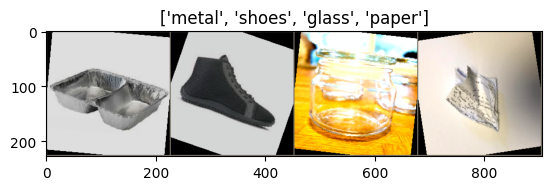

In [11]:
import matplotlib.pyplot as plt
import numpy as np

def imshow(inp, title=None):
    inp = inp.numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    inp = std * inp + mean
    inp = np.clip(inp, 0, 1)
    plt.imshow(inp)
    if title is not None:
        plt.title(title)
    plt.pause(0.001)

inputs, classes = next(iter(train_loader))

import torchvision
out = torchvision.utils.make_grid(inputs[:4])

imshow(out, title=[class_names[x] for x in classes[:4]])

## Model Selection — EfficientNet-B6

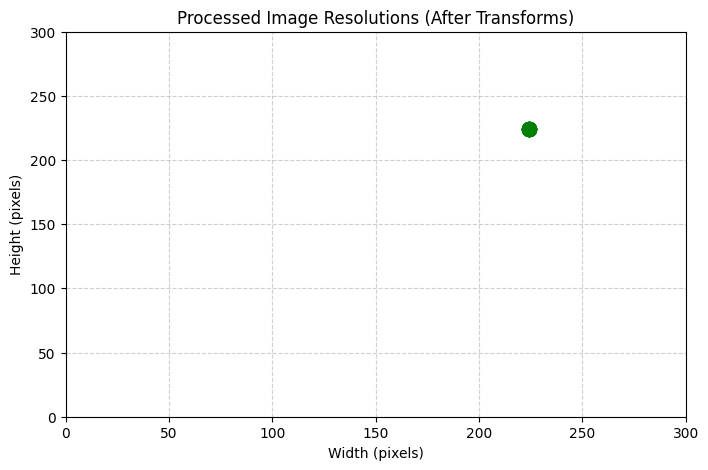

Shape of a single image tensor: torch.Size([3, 224, 224])
Standardized Resolution: 224x224


In [12]:
import matplotlib.pyplot as plt


images, labels = next(iter(train_loader))

batch_heights = [images.shape[2]] * len(images)
batch_widths = [images.shape[3]] * len(images)

plt.figure(figsize=(8, 5))
plt.scatter(batch_widths, batch_heights, color='green', s=100)
plt.xlim(0, 300)
plt.ylim(0, 300)
plt.xlabel('Width (pixels)')
plt.ylabel('Height (pixels)')
plt.title('Processed Image Resolutions (After Transforms)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

print(f"Shape of a single image tensor: {images[0].shape}")
print(f"Standardized Resolution: {images.shape[3]}x{images.shape[2]}")

Model training

In [13]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models

# Device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f'Using device: {device}')

if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')


# Load ImageNet-pretrained EfficientNet-B6
model_eff_b6 = models.efficientnet_b6(
    weights='IMAGENET1K_V1'
)

# Replace the original ImageNet classifier with a 10-class classifier
num_ftrs_b6 = model_eff_b6.classifier[1].in_features

model_eff_b6.classifier[1] = nn.Linear(
    num_ftrs_b6,
    len(class_names)
)

model_eff_b6 = model_eff_b6.to(device)

print("EfficientNet-B6 initialized successfully.")
print(f"Number of output classes: {len(class_names)}")

Using device: cuda
GPU: Tesla T4
Downloading: "https://download.pytorch.org/models/efficientnet_b6_lukemelas-24a108a5.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b6_lukemelas-24a108a5.pth


100%|██████████| 165M/165M [00:01<00:00, 121MB/s]


EfficientNet-B6 initialized successfully.
Number of output classes: 10


In [14]:
def train_model(model, criterion, optimizer, num_epochs=3):
    model.to(device)

    for epoch in range(num_epochs):

        model.train()

        running_loss = 0.0
        running_corrects = 0
        total_samples = 0

        for inputs, labels in train_loader:

            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(inputs)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            _, preds = torch.max(outputs, 1)

            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels).item()
            total_samples += labels.size(0)

        epoch_loss = running_loss / total_samples
        epoch_acc = 100 * running_corrects / total_samples

        print(
            f'Epoch {epoch + 1}/{num_epochs} | '
            f'Loss: {epoch_loss:.4f} | '
            f'Training Accuracy: {epoch_acc:.2f}%'
        )


criterion = nn.CrossEntropyLoss()

optimizer_b6 = optim.Adam(
    model_eff_b6.parameters(),
    lr=0.001
)

print('--- Training EfficientNet-B6 ---')

train_model(
    model_eff_b6,
    criterion,
    optimizer_b6,
    num_epochs=3
)

--- Training EfficientNet-B6 ---
Epoch 1/3 | Loss: 0.9129 | Training Accuracy: 70.98%
Epoch 2/3 | Loss: 0.5980 | Training Accuracy: 81.65%
Epoch 3/3 | Loss: 0.4706 | Training Accuracy: 84.90%


Saving EfficientNet-B6 Weights

In [15]:
import torch

torch.save(
    model_eff_b6.state_dict(),
    'garbage_eff_b6.pth'
)

print("EfficientNet-B6 weights saved successfully.")

EfficientNet-B6 weights saved successfully.


Validation Evaluation

In [16]:
def evaluate_model(model, loader):

    model.to(device)
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():

        for inputs, labels in loader:

            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)

            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total

    return accuracy


val_acc = evaluate_model(
    model_eff_b6,
    val_loader
)

print(
    f'EfficientNet-B6 Validation Accuracy: '
    f'{val_acc:.2f}%'
)

EfficientNet-B6 Validation Accuracy: 85.10%


Fine-tuning EfficientNet-B6

In [17]:
print('--- Fine-tuning EfficientNet-B6 ---')

optimizer_b6_fine = optim.Adam(
    model_eff_b6.parameters(),
    lr=0.0001
)

torch.cuda.empty_cache()

train_model(
    model_eff_b6,
    criterion,
    optimizer_b6_fine,
    num_epochs=2
)

new_val_acc = evaluate_model(
    model_eff_b6,
    val_loader
)

print(
    f'Updated Validation Accuracy: '
    f'{new_val_acc:.2f}%'
)

--- Fine-tuning EfficientNet-B6 ---
Epoch 1/2 | Loss: 0.2649 | Training Accuracy: 91.39%
Epoch 2/2 | Loss: 0.1740 | Training Accuracy: 94.23%
Updated Validation Accuracy: 93.47%


training graphs

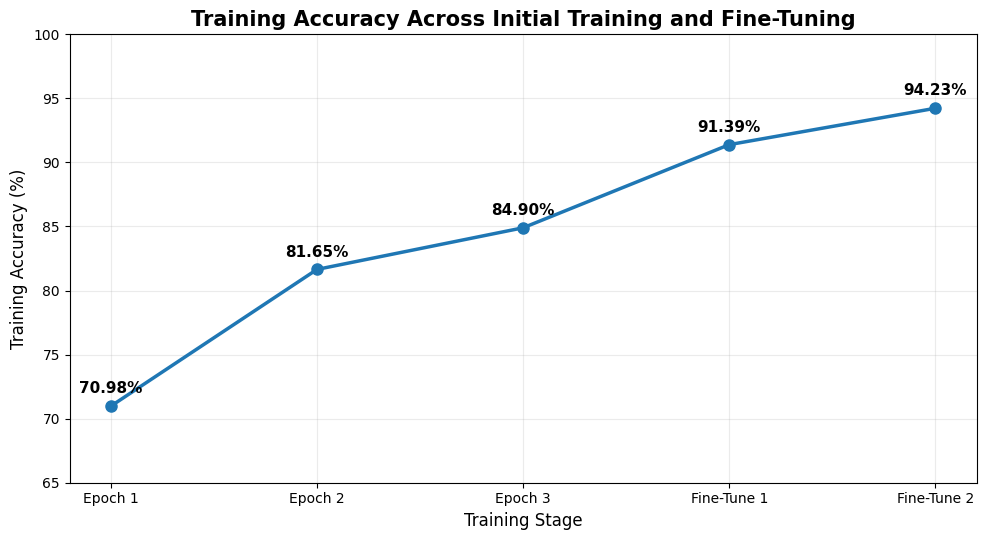

In [28]:
import matplotlib.pyplot as plt

stages = [
    "Epoch 1",
    "Epoch 2",
    "Epoch 3",
    "Fine-Tune 1",
    "Fine-Tune 2"
]

accuracy = [70.98, 81.65, 84.90, 91.39, 94.23]

plt.figure(figsize=(10, 5.5))

plt.plot(
    stages,
    accuracy,
    marker="o",
    linewidth=2.5,
    markersize=8
)

# Show exact accuracy above each point
for x, y in zip(stages, accuracy):
    plt.text(
        x,
        y + 1,
        f"{y:.2f}%",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

plt.title(
    "Training Accuracy Across Initial Training and Fine-Tuning",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Training Stage", fontsize=12)
plt.ylabel("Training Accuracy (%)", fontsize=12)

plt.ylim(65, 100)
plt.grid(alpha=0.25)
plt.tight_layout()

plt.show()

final test evolution

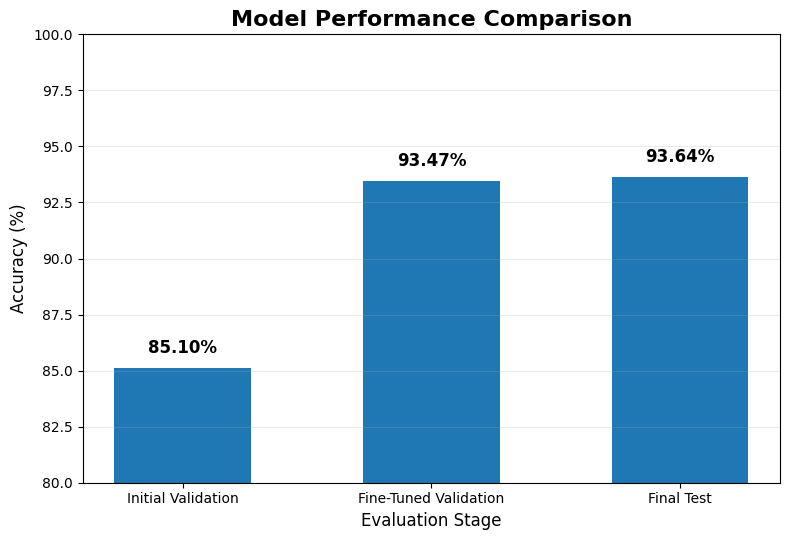

In [29]:
import matplotlib.pyplot as plt

stages = [
    "Initial Validation",
    "Fine-Tuned Validation",
    "Final Test"
]

accuracy = [85.10, 93.47, 93.64]

plt.figure(figsize=(8, 5.5))

bars = plt.bar(stages, accuracy, width=0.55)

# Add exact values above bars
for bar, value in zip(bars, accuracy):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.5,
        f"{value:.2f}%",
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold"
    )

plt.title(
    "Model Performance Comparison",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Evaluation Stage", fontsize=12)
plt.ylabel("Accuracy (%)", fontsize=12)

plt.ylim(80, 100)
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

In [18]:
torch.save(
    model_eff_b6.state_dict(),
    'garbage_eff_b6_finetuned.pth'
)

print(
    'Fine-tuned EfficientNet-B6 saved successfully.'
)

Fine-tuned EfficientNet-B6 saved successfully.


Final Test Set Evaluation

In [19]:
print(
    'Evaluating EfficientNet-B6 '
    'on the held-out test set...'
)

test_acc = evaluate_model(
    model_eff_b6,
    test_loader
)

print(
    f'Final Test Accuracy: {test_acc:.2f}%'
)

Evaluating EfficientNet-B6 on the held-out test set...
Final Test Accuracy: 93.64%


Saving Full Models (Structure + Weights)

In [20]:
import torch
torch.save(
    model_eff_b6,
    'garbage_full_eff_b6.pth'
)

print(
    "Full EfficientNet-B6 model saved."
)

Full EfficientNet-B6 model saved.


Drive access

In [21]:
from google.colab import drive
import os

drive.mount('/content/drive', force_remount=True)

shared_path = '/content/drive/MyDrive/garbage-classification'

if os.path.exists(shared_path):
    print("Successfully accessed folder!")
    print("Available models:", [f for f in os.listdir(shared_path) if f.endswith('.pth')])
else:
    print("Folder not found. Make sure you shared it and added a shortcut to 'My Drive' in the second account.")

Mounted at /content/drive
Folder not found. Make sure you shared it and added a shortcut to 'My Drive' in the second account.


 Model Evaluation Visualization,confusion matrix


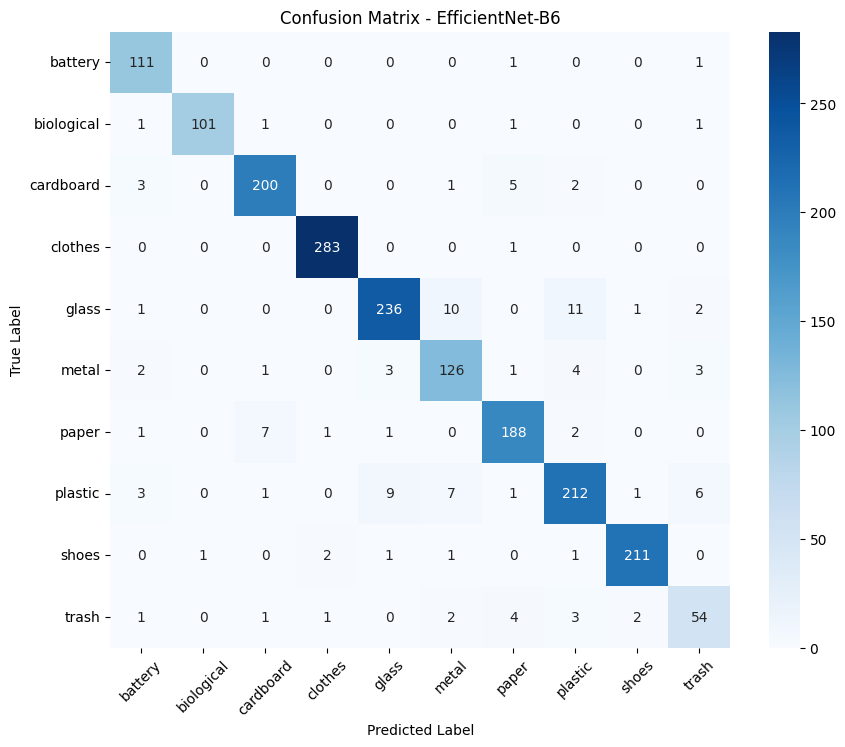

In [22]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import numpy as np

def plot_confusion_matrix(model, loader, classes):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in loader:
            inputs = inputs.to(device)
            labels = labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    cm = confusion_matrix(all_labels, all_preds)

    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=classes, yticklabels=classes)
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.title('Confusion Matrix - EfficientNet-B6')
    plt.xticks(rotation=45)
    plt.show()

plot_confusion_matrix(model_eff_b6, test_loader, class_names)

classification report


In [23]:
from sklearn.metrics import classification_report

def get_predictions(model, loader):

    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():

        for inputs, labels in loader:

            inputs = inputs.to(device)

            outputs = model(inputs)

            _, preds = torch.max(outputs, 1)

            all_preds.extend(
                preds.cpu().numpy()
            )

            all_labels.extend(
                labels.numpy()
            )

    return all_labels, all_preds


true_labels, predictions = get_predictions(
    model_eff_b6,
    test_loader
)

print(
    classification_report(
        true_labels,
        predictions,
        target_names=class_names,
        digits=4
    )
)

              precision    recall  f1-score   support

     battery     0.9024    0.9823    0.9407       113
  biological     0.9902    0.9619    0.9758       105
   cardboard     0.9479    0.9479    0.9479       211
     clothes     0.9861    0.9965    0.9912       284
       glass     0.9440    0.9042    0.9237       261
       metal     0.8571    0.9000    0.8780       140
       paper     0.9307    0.9400    0.9353       200
     plastic     0.9021    0.8833    0.8926       240
       shoes     0.9814    0.9724    0.9769       217
       trash     0.8060    0.7941    0.8000        68

    accuracy                         0.9364      1839
   macro avg     0.9248    0.9283    0.9262      1839
weighted avg     0.9368    0.9364    0.9364      1839



Deploy

In [2]:
!pip install -q gradio

import gradio as gr
import torch
from torchvision import transforms, models
import torch.nn as nn

device = torch.device(
    'cuda' if torch.cuda.is_available()
    else 'cpu'
)

# Recreate EfficientNet-B6
deployment_model = models.efficientnet_b6(
    weights=None
)

num_ftrs = deployment_model.classifier[1].in_features

deployment_model.classifier[1] = nn.Linear(
    num_ftrs,
    len(class_names)
)

# Load trained weights
model_path = 'garbage_eff_b6_finetuned.pth'

deployment_model.load_state_dict(
    torch.load(
        model_path,
        map_location=device
    )
)

deployment_model.to(device)

deployment_model.eval()


inference_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])


def predict_garbage(image):

    image = image.convert('RGB')

    input_tensor = (
        inference_transform(image)
        .unsqueeze(0)
        .to(device)
    )

    with torch.no_grad():

        outputs = deployment_model(
            input_tensor
        )

        probabilities = torch.softmax(
            outputs[0],
            dim=0
        )

    return {
        class_names[i]:
        float(probabilities[i])
        for i in range(len(class_names))
    }


interface = gr.Interface(
    fn=predict_garbage,
    inputs=gr.Image(type="pil"),
    outputs=gr.Label(
        num_top_classes=5
    ),
    title="Garbage Classification System",
    description=(
        "Upload a garbage image "
        "for EfficientNet-B6 classification."
    )
)

interface.launch(
    share=False,
    debug=True
)

NameError: name 'class_names' is not defined